# 04 · Higher-order interactions (O-information)

Visualises `src/higher_order` output (run `python -m src.higher_order.run`). Gaussian O-information of all region
triplets: Ω > 0 redundancy-dominated, Ω < 0 synergy-dominated.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import pickle
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from src.core import paths
from src.core.data import GROUPS, load_data, load_model_results, load_features

sns.set_theme(style="whitegrid", context="notebook")
PALETTE = {"HC": "#2a9d8f", "AP": "#e76f51", "NAP": "#e9c46a"}

In [2]:
from src.core.measures import triplet_oinfo, copula_normalize
D = paths.DERIVED / "higher_order"
S = pd.read_csv(D / "subject_measures.csv")
G = pd.read_csv(D / "group_tests.csv")
Gc = pd.read_csv(D / "group_tests_compositions.csv")
MV = pd.read_csv(D / "model_vs_empirical.csv")
display(G.round(4))

,measure,mean_HC,mean_AP,mean_NAP,F,p_perm,g_AP_vs_HC,g_NAP_vs_HC,g_NAP_vs_AP,q_FDR
0,Omega_mean,0.0584,0.0404,0.0440,2.6674,0.0726,-0.4376,-0.3586,0.1052,0.1207
1,syn_frac,0.2243,0.2811,0.2709,2.3597,0.0956,0.4100,0.3499,-0.0818,0.1207
2,TC_mean,0.4315,0.3689,0.3834,2.3797,0.0966,-0.4307,-0.3364,0.1117,0.1207
3,Omega_mean_pearson,0.0615,0.0424,0.0476,2.4349,0.0874,-0.4431,-0.3256,0.1424,0.1207
4,syn_frac_pearson,0.2246,0.2795,0.2668,2.0033,0.1330,0.3925,0.3139,-0.1002,0.1330


## Global O-information by group

/tmp/ipykernel_435035/3456516014.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=S, x="group", y=m, order=GROUPS, palette=PALETTE, ax=ax, showfliers=False)
/tmp/ipykernel_435035/3456516014.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=S, x="group", y=m, order=GROUPS, palette=PALETTE, ax=ax, showfliers=False)
/tmp/ipykernel_435035/3456516014.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=S, x="group", y=m, order=GROUPS, palette=PALETTE, ax=ax, showfliers=False)


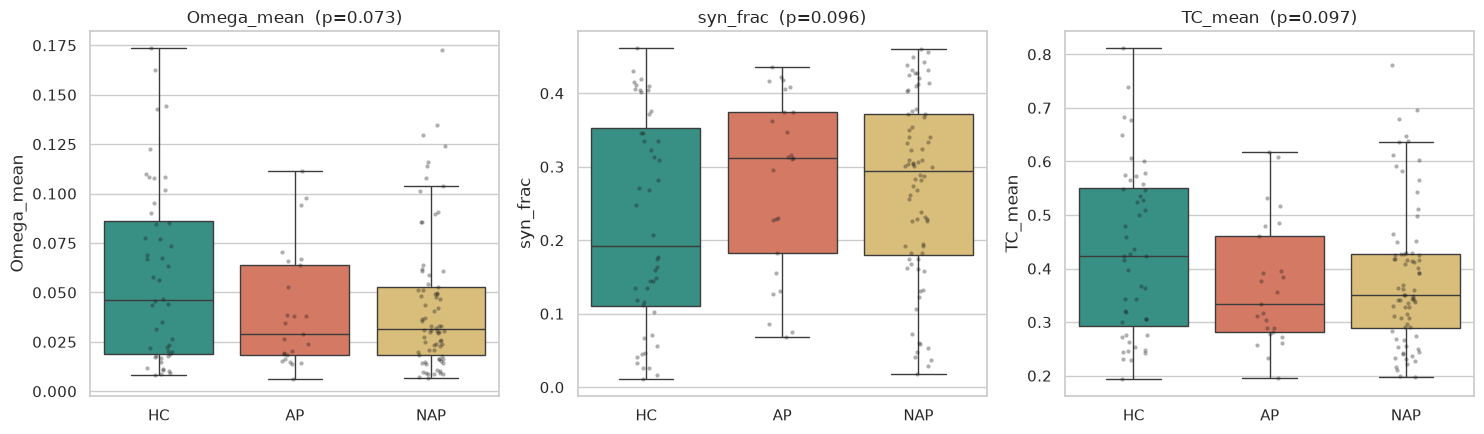

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, m in zip(axes, ("Omega_mean", "syn_frac", "TC_mean")):
    sns.boxplot(data=S, x="group", y=m, order=GROUPS, palette=PALETTE, ax=ax, showfliers=False)
    sns.stripplot(data=S, x="group", y=m, order=GROUPS, color="k", alpha=.35, size=3, ax=ax)
    r = G.set_index("measure").loc[m]; ax.set_title(f"{m}  (p={r.p_perm:.3f})"); ax.set_xlabel("")
plt.tight_layout(); plt.show()

## Triplet O-information distribution, one subject: empirical vs GEC model

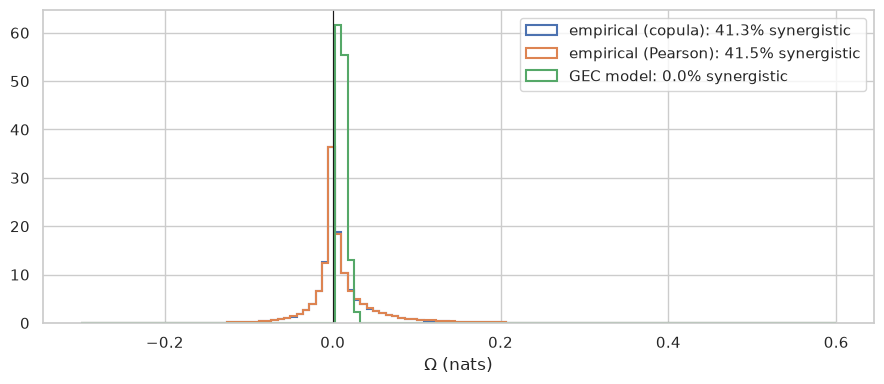

In [4]:
ts, _, _ = load_data(); res = load_model_results()["results"]
g, k = "NAP", 0
om_cop, _ = triplet_oinfo(np.corrcoef(copula_normalize(ts[g][k])))
om_emp, _ = triplet_oinfo(np.corrcoef(ts[g][k]))
om_mod, _ = triplet_oinfo(res[g][k]["FC_sim"])
fig, ax = plt.subplots(figsize=(9, 4))
bins = np.linspace(-0.3, 0.6, 120)
for v, lab in ((om_cop, "empirical (copula)"), (om_emp, "empirical (Pearson)"), (om_mod, "GEC model")):
    ax.hist(v, bins=bins, histtype="step", lw=1.5, density=True, label=f"{lab}: {np.mean(v < 0):.1%} synergistic")
ax.axvline(0, color="k", lw=.8); ax.set_xlabel("Ω (nats)"); ax.legend()
plt.tight_layout(); plt.show()

## Can the linear model produce synergy?

,k,Omega_mean_emp,Omega_mean_model,syn_frac_emp,syn_frac_model,r_triplets_emp_model
group,,,,,,
AP,12.0,0.0424,0.0386,0.2795,0.0,0.6689
HC,23.5,0.0615,0.0504,0.2246,0.0,0.6704
NAP,37.5,0.0476,0.0428,0.2668,0.0,0.6510


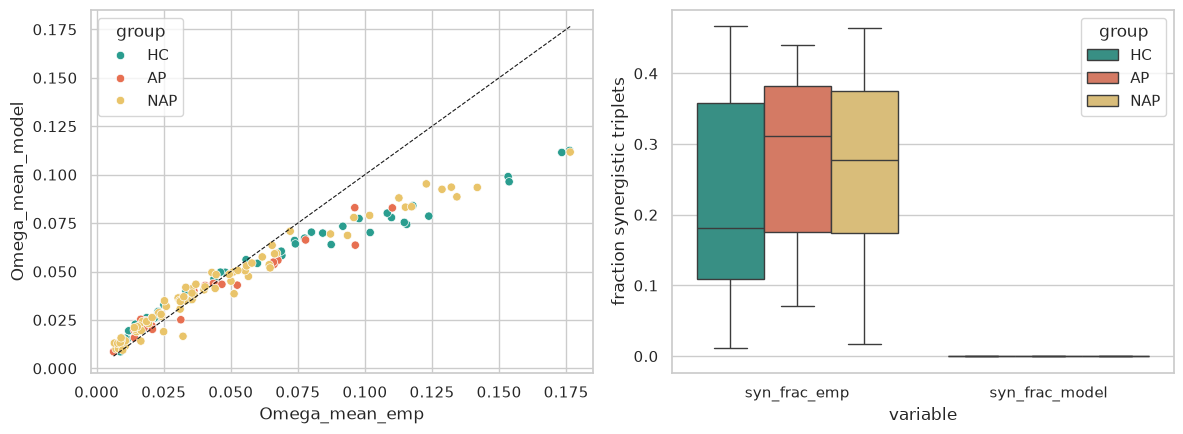

In [5]:
display(MV.groupby("group").mean(numeric_only=True).round(4))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.scatterplot(data=MV, x="Omega_mean_emp", y="Omega_mean_model", hue="group", palette=PALETTE, ax=axes[0])
lim = [MV[["Omega_mean_emp", "Omega_mean_model"]].min().min(), MV[["Omega_mean_emp", "Omega_mean_model"]].max().max()]
axes[0].plot(lim, lim, "k--", lw=.8)
sns.boxplot(data=MV.melt(id_vars="group", value_vars=["syn_frac_emp", "syn_frac_model"]), x="variable", y="value",
            hue="group", palette=PALETTE, ax=axes[1])
axes[1].set_ylabel("fraction synergistic triplets")
plt.tight_layout(); plt.show()

## Network compositions with the largest group effects

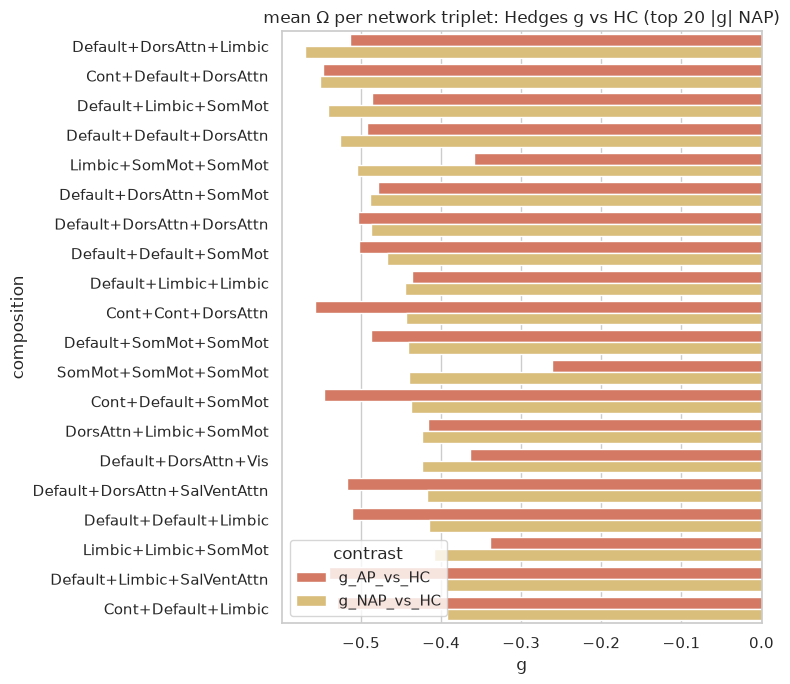

,composition,mean_HC,mean_AP,mean_NAP,p_perm,g_AP_vs_HC,g_NAP_vs_HC,q_FDR
35,Default+DorsAttn+Limbic,0.0343,0.0150,0.0148,0.0070,-0.5134,-0.5701,0.1304
8,Cont+Default+DorsAttn,0.0329,0.0124,0.0139,0.0035,-0.5469,-0.5518,0.1304
41,Default+Limbic+SomMot,0.0346,0.0182,0.0180,0.0095,-0.4867,-0.5408,0.1304
29,Default+Default+DorsAttn,0.0254,0.0078,0.0077,0.0105,-0.4921,-0.5264,0.1304
71,Limbic+SomMot+SomMot,0.0723,0.0518,0.0463,0.0230,-0.3584,-0.5051,0.1304
37,Default+DorsAttn+SomMot,0.0445,0.0242,0.0248,0.0140,-0.4790,-0.4894,0.1304
34,Default+DorsAttn+DorsAttn,0.0445,0.0228,0.0249,0.0130,-0.5032,-0.4871,0.1304
32,Default+Default+SomMot,0.0392,0.0195,0.0222,0.0140,-0.5026,-0.4680,0.1304
39,Default+Limbic+Limbic,0.0367,0.0194,0.0207,0.0270,-0.4362,-0.4452,0.1304
2,Cont+Cont+DorsAttn,0.0580,0.0310,0.0374,0.0145,-0.5572,-0.4444,0.1304


In [6]:
top = Gc.reindex(Gc.g_NAP_vs_HC.abs().sort_values(ascending=False).index).head(20)
fig, ax = plt.subplots(figsize=(8, 7))
d = top.melt(id_vars="composition", value_vars=["g_AP_vs_HC", "g_NAP_vs_HC"], var_name="contrast", value_name="g")
sns.barplot(data=d, y="composition", x="g", hue="contrast", palette=[PALETTE["AP"], PALETTE["NAP"]], ax=ax)
ax.axvline(0, color="k", lw=.8); ax.set_title("mean Ω per network triplet: Hedges g vs HC (top 20 |g| NAP)")
plt.tight_layout(); plt.show()
display(top.round(4))

## Symptom correlations

In [7]:
display(pd.read_csv(D / "symptom_correlations.csv").sort_values("p_perm").round(4))

,target,measure,rho_partial,p_perm,n,q_FDR
2,PANSS,TC_mean,0.0587,0.5853,92,0.8956
7,YMRS,TC_mean,0.0462,0.6477,98,0.7636
8,YMRS,Omega_mean_pearson,0.0453,0.6611,98,0.7636
9,YMRS,syn_frac_pearson,-0.0434,0.6703,98,0.7636
6,YMRS,syn_frac,-0.0406,0.6951,98,0.7636
0,PANSS,Omega_mean,0.0326,0.7578,92,0.8956
5,YMRS,Omega_mean,0.0319,0.7636,98,0.7636
1,PANSS,syn_frac,-0.0301,0.7734,92,0.8956
3,PANSS,Omega_mean_pearson,0.0173,0.8704,92,0.8956
4,PANSS,syn_frac_pearson,-0.0134,0.8956,92,0.8956
